In [16]:
from Run_Designs import design_experiments, design_initial_experiments
from methods.DataPrep import dataprep
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

Design Variable

1. C - List of number of categroies corresponding to each categorical variable
2. Nc - Number of categorical variables
3. Nx - Continuous variables
4. h - categorical
5. x - continuous
6. z - [h, x]
7. nDim - Nc + Nx
8. bounds - Lower and Upper bounds of both Catergorical variables and continuous variables
9. Var_unsc - Variables that shouldn't be scaled in the model

Sample Collection Details

10. n_iter - Number of iterations to run the algorithm
11. initN - Number of intial data points
12. batch_size (b) - Number of experiments to be generated in each iteration

Optimization Problem details
13. approach_type (type of design space)
    - Single system/task learning - CoCa (Continuous Categorical) vs Co (Continuous)
    - Multi system/task learning - CoCa_ICM, CoCa_LCM, CoCa_LEK, CoCa_LEK_precompute, 
    Co_ICM, Co_LCM, Co_LEK, Co_LEK_precompute
    
14. prob_type - 'UnConstrained' vs 'Constrained' (type of optimization problem)
15. method - 'thompson sampling' vs 'constant_liar' (type of sampling)
16. Meas_Noise - Measurement Noise in the target 
17. trade_off : Explorarion exploitation balance

Multitask/TL details

17. Noutput : Number of different systems in the data. Needed for multi-task or transfer learning application (System ID is always in the last column of the dataset)
18. if approach type for multi-task is ICM or LCM --> W_rank is a required parameter for the model. if approach type is LEK based then N_latent is required. Default W_rank = 1. Default N_latent = 2
19.



In [2]:
Stock_solid = pd.read_excel('CarbonSourceInfo.xlsx', 'Stocks_solid')
Stock_liquid = pd.read_excel('CarbonSourceInfo.xlsx', 'Stocks_liquid')

Carbon_Names = Stock_solid['Carbon Source'].values.tolist()
Carbon_Names.append(Stock_liquid['Carbon Source'][1])
Carbon_Names.append(Stock_liquid['Carbon Source'][2])

Carbon_Ub = [50]*17 #[g/L]
Carbon_Ub.append(10) # Glycerol [mL/L]
Carbon_Ub.append(50) #Ethanol [mL/L]

### Start with HSA independent CoCaBO

In [3]:
Mol_List = ['KPhaffii_HSA'] #, 'KPhaffii_RBDJ', 'Kphaffii_Trastuzumab'
Data_Molecules = {}
for m in Mol_List:
    Data_Molecules[m] = pd.read_excel("KPhaffii_Experiments.xlsx", m).iloc[:,1:]
    for i in range(Data_Molecules[m].shape[0]):
        Data_Molecules[m].iloc[i,0] = Carbon_Names.index(Data_Molecules[m].iloc[i,0])
        Data_Molecules[m].iloc[i,1] = Data_Molecules[m].iloc[i,1]/Carbon_Ub[Data_Molecules[m].iloc[i,0]]
        Data_Molecules[m].iloc[i,2:4] = Data_Molecules[m].iloc[i,2:4]/10
        
data_modified_np = {}
result_modified_np = {}
cnt_m = 0
for m in Mol_List:
    data_modified = []
    result_modified = []
    data_init = Data_Molecules[m].iloc[:,0:4].values.astype('float64')
    result_init = Data_Molecules[m]['SP [mg/L/OD600]'].values.reshape(-1,1).astype('float64')
    for nc in range(data_init.shape[0]):
        data_modified.append(data_init[nc, :])
        result_modified.append(result_init[nc])
    
    temp1 = np.array(data_modified)
    data_modified_np[m] = np.concatenate((temp1, cnt_m*np.ones((temp1.shape[0], 1))), axis =1)
    result_modified_np[m] = np.array(result_modified).reshape(-1,1)
    
    cnt_m = cnt_m+1

### Add RBDJ data from first TL attempt CoCaLEK

In [4]:
data = data_modified_np['KPhaffii_HSA']
result = result_modified_np['KPhaffii_HSA']

print(data.shape)

Nround = 6
path_rbdj = '../Exp/RBDJ/'
path_rbdj_code = '../Codes'

for r in range(Nround):
    data_modified = []
    result_modified = []
    dat_read = pd.read_csv(path_rbdj_code+"/Round"+str(r)+'/Reconstructed_Round'+str(r)+"_CoCaLEK.csv").iloc[:,1:].values #Reconstructed_
    result_new = pd.read_csv(path_rbdj+"Round" +str(r)+"_CoCaLEK/Round" + str(r) +"_Result_Summary_final.csv")['Specific Productivity'].values.reshape(-1,1)

    for nc in range(dat_read.shape[0]):
        data_modified.append(dat_read[nc, :])
        result_modified.append(result_new[nc])
    
    temp1 = np.array(data_modified)
    data_new = np.concatenate((temp1, 1*np.ones((temp1.shape[0], 1))), axis =1)
    result_new_np = np.array(result_modified).reshape(-1,1)
    
    
    data = np.concatenate((data, data_new), axis = 0)
    result = np.concatenate((result, result_new_np), axis = 0)
print(data.shape)

(84, 5)
(150, 5)


In [5]:
import pickle
fnl = "Embedding_HSA_RBDJ.pkl"
with open(fnl, "rb") as fp:
    Wembed_init = pickle.load(fp)

In [6]:
initN = 23
Nc = 2
C_list = [3, 19] #
assert Nc == len(C_list)
Nx = 3
nDim = Nc + Nx
Niter = 1
batch_size = 11
bounds = [{'name': 'Carbon_Type', 'type': 'categorical', 'domain': np.arange(0, 19)}, #Carbon Source type
          {'name': 'Conc_Carbon', 'type': 'continuous', 'domain': (0, 1)},
            {'name': 'Gly_OG', 'type': 'continuous', 'domain': (0, 1)},
            {'name': 'Met_Prod', 'type': 'continuous', 'domain': (0, 1)}]

#0 - lb and 1 - ub
data_param = {'C': C_list, 'Nc': Nc, 'Nx': Nx, 'nDim': Nc+Nx, 'bounds': bounds, 'approach_type':'CoCa',
'prob_type': 'UnConstrained', 'initN': initN, 'trade_off': 3, 'Meas_Noise':0.1, 'batch_size': 11}

data_param_CoCaLEK = data_param.copy()
data_param_CoCaLEK['Nc'] = 1
data_param_CoCaLEK['C'] =  [19]
data_param_CoCaLEK['nDim'] = data_param_CoCaLEK['Nc'] + data_param_CoCaLEK['Nx']

data_param_CoCaLEK['approach_type'] = 'CoCa_LEK_precompute'
data_param_CoCaLEK['Noutput'] = 3
data_param_CoCaLEK['Nlatent'] = 2
data_param_CoCaLEK['N_precompute'] = 2
data_param_CoCaLEK['W_pre'] = Wembed_init
data_param_CoCaLEK['LorO'] = 'O'



data_param_CoCaLEK['Var_unsc'] = list(np.arange(0, data_param_CoCaLEK['Nc'])) + list(np.arange(data_param_CoCaLEK['nDim'],
                                               data_param_CoCaLEK['nDim'] + data_param_CoCaLEK['Noutput']))
data_param_CoCaLEK['BiasTL'] = True
data_param_CoCaLEK['SampleSystem'] = False
data_param_CoCaLEK['SystemID'] = 2
cont_kernel_name = 'Matern52'


key = 'CoCa_LEK_precompute'
data_mod = dataprep(data, data_param_CoCaLEK, key)

In [7]:
random_seed = 37
background_model_parameter = 'pre_ModelBackground_CoCaLEK_fix.pkl'
Exp0 = design_initial_experiments(data_param_CoCaLEK, initN, 'dummy_file.csv', 
                                  random_seed, background_model_parameter)

In [8]:
method = 'constant_liar'
batch_size = 11
output_file_name = './Round0/Round0_CoCaLEK_fix'
background_model_parameter = 'pre_ModelBackground_CoCaLEK_fix.pkl'
new_model_parameter = './Round0/0_ModelBackground_CoCaLEK_fix.pkl'

z_next, gp_actual = design_experiments(data_mod, result,batch_size, method,background_model_parameter, 
                            new_model_parameter , output_file_name)

3
  mul.                                           |                value  |  constraints  |  priors
  sum.MixtureViaSumAndProduct.mix                |  0.14176949998614147  |      +ve      |        
  sum.MixtureViaSumAndProduct.Mat52.lengthscale  |                 (3,)  |      +ve      |        
  sum.white.variance                             |                  0.1  |   +ve fixed   |        
  latentVariable.Wembedding                      |               (3, 2)  |   -3.0,3.0    |        
0
(5000, 4)
1
[15.          0.05132783  0.24931607  0.12657987  0.          0.
  1.        ]
1
(5000, 4)
1
[8.         0.99348483 0.09591679 0.08824862 0.         0.
 1.        ]
2
(5000, 4)
1
[5.         0.01460896 0.74358328 0.98090791 0.         0.
 1.        ]
3
(5000, 4)
1
[12.          0.95961256  0.91773077  0.96542263  0.          0.
  1.        ]
4
(5000, 4)
1
[7.00000000e+00 4.66071269e-05 5.95032064e-01 2.12961960e-02
 0.00000000e+00 0.00000000e+00 1.00000000e+00]
5
(5000, 4)
1
[9.      

In [9]:
gp_actual.mul.latentVariable.Wembedding

AttributeError: 'GPRegression' object has no attribute 'mul'

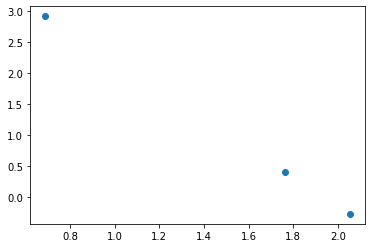

In [17]:
import pickle
fnl = './Round0/0_ModelBackground_CoCaLEK_fix.pkl'
with open(fnl, "rb") as fp:
    background = pickle.load(fp)

embed = background['Categorical_dist_param']['Wembed_updated']
plt.scatter(embed[0,0], embed[0,1])

In [11]:
Wembed_init

{'gamma_list': [0.09078024230464467],
 'budget': 100,
 'bestUpperBoundEstimate': 66.66666666666667,
 'Wc_list_init': [array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1.])],
 'Wc_list': [array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
         1., 1.])],
 'data_param': {'C': [19],
  'Nc': 1,
  'Nx': 3,
  'nDim': 4,
  'bounds': [{'name': 'Carbon_Type',
    'type': 'categorical',
    'domain': array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
           17, 18])},
   {'name': 'Conc_Carbon', 'type': 'continuous', 'domain': (0, 1)},
   {'name': 'Gly_OG', 'type': 'continuous', 'domain': (0, 1)},
   {'name': 'Met_Prod', 'type': 'continuous', 'domain': (0, 1)}],
  'approach_type': 'CoCa_LEK_precompute',
  'prob_type': 'UnConstrained',
  'initN': 23,
  'trade_off': 3,
  'Meas_Noise': 0.1,
  'batch_size': 11,
  'Noutput': 3,
  'Nlatent': 2,
  'N_precompute': 2,
  'W_pre': array([[ 2.05344647, -0.27816756]

In [12]:
import pickle
fnl = 'Embedding_HSA_RBDJ.pkl'
with open(fnl, "rb") as fp:
    Wembed_init = pickle.load(fp)

In [13]:
Wembed_init

array([[ 2.05344647, -0.27816756],
       [ 0.68934386,  2.91921797]])